<a href="https://colab.research.google.com/github/TasminaTasin75/COMP6012-Assignment-4-LLM-Ecommerce-Agent/blob/main/llm_agent_for_ecom_assignment_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# COMP6012 Assignment 4 — LLM-based eCommerce Agent
**Three main tasks**
1. **Advertisement Generation** — match images, generate slogans and advanced features.
2. **Product Recommendation** — list matching phones and recommend the best.
3. **Customer Review Analysis** — sentiment, key feedback, improvement suggestions.


In [1]:
# Install required libraries
%pip install -q "transformers==5.21.0" "accelerate>=1.4" "bitsandbytes==0.49.0" "peft" \
    "sentence-transformers" "kagglehub" "gradio>=6,<7"

**Basic Setup and data inspection**

Basic library import and random seed fix

In [2]:
# Basic library imports
import torch
import numpy as np
import pandas as pd
from transformers import set_seed

SEED = 42
set_seed(SEED)   # same random results each run

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)
if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


**Loading the image dataset**
About 140 smartphone images with short captions, from Hugging Face.

In [3]:
# Load the image dataset
from datasets import load_dataset

image_dataset = load_dataset("daekeun-ml/mobile-icons-poc")
print(image_dataset)

README.md:   0%|          | 0.00/397 [00:00<?, ?B/s]

data/train-00000-of-00001-da1d7eb613a82b(…): reconstructing file:   0%|          |  0.00B / 19.0MB            

data/train-00000-of-00001-da1d7eb613a82b(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/140 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'text'],
        num_rows: 140
    })
})


**Viewing sample images**

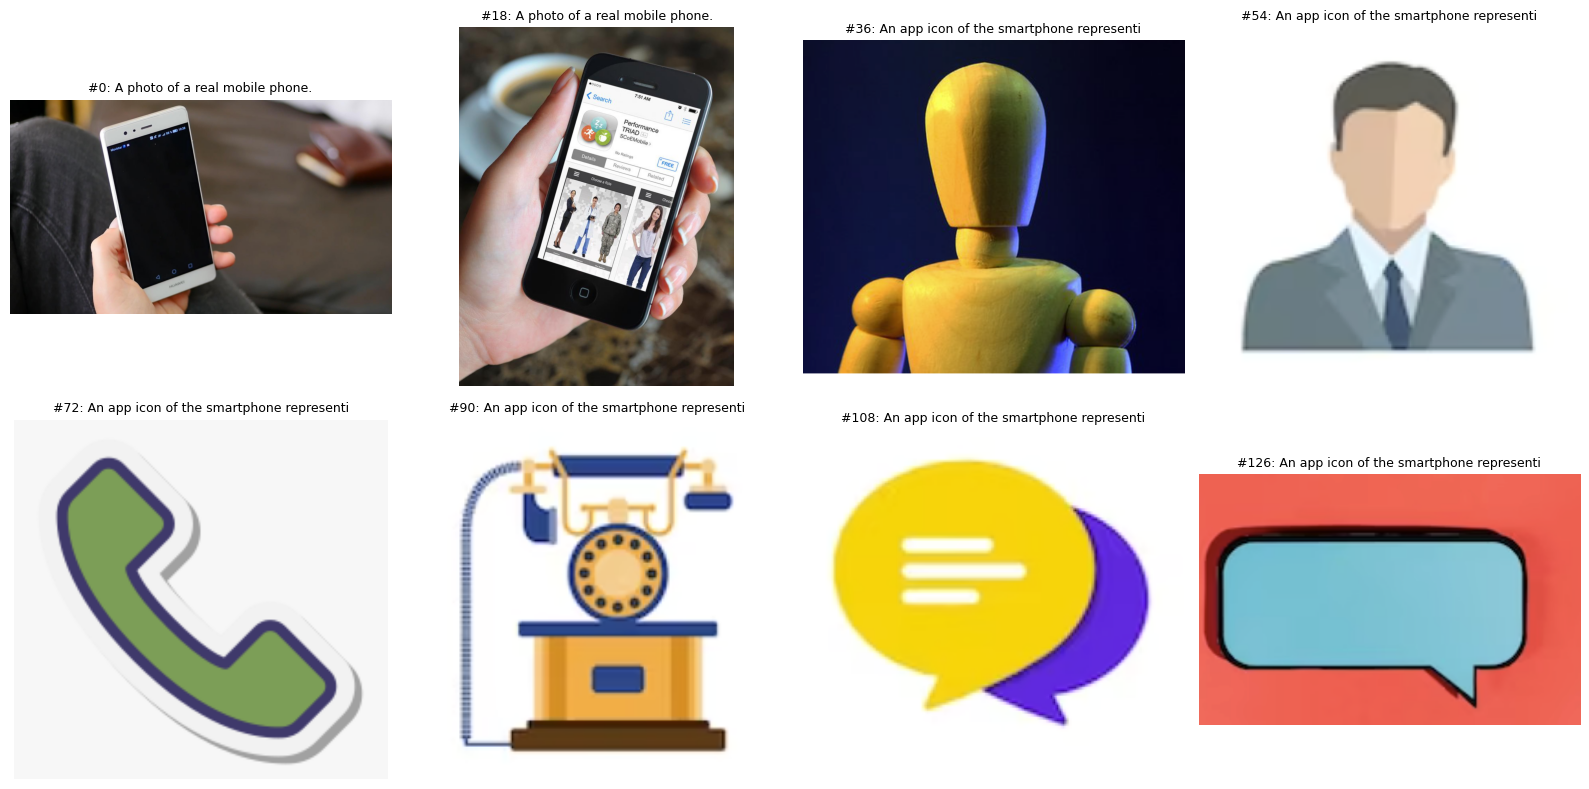

In [4]:
# View sample images with captions
import matplotlib.pyplot as plt

images = image_dataset["train"]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, idx in zip(axes.ravel(), range(0, 140, 18)):   # 8 images spread across the dataset
    ax.imshow(images[idx]["image"])
    ax.set_title(f"#{idx}: {images[idx]['text'][:40]}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

**Caption summary**

In [5]:
# Caption types and full captions
captions = pd.Series(images["text"])

# Group by the start of the caption to see the image types
caption_type = captions.str.split().str[:4].str.join(" ")
print("Caption types:")
print(caption_type.value_counts())

print("\nSome full captions:")
for idx in [0, 18, 36, 54, 72, 90]:
    print(f"#{idx}: {captions[idx]}")

Caption types:
An app icon of    105
A photo of a       35
Name: count, dtype: int64

Some full captions:
#0: A photo of a real mobile phone.
#18: A photo of a real mobile phone.
#36: An app icon of the smartphone representing the person avatar.
#54: An app icon of the smartphone representing the person avatar.
#72: An app icon of the smartphone representing the phone.
#90: An app icon of the smartphone representing the phone.


In [6]:
# get all unique captions and their counts
print("Unique captions:", captions.nunique())
print(captions.value_counts())

Unique captions: 4
A photo of a real mobile phone.                                  35
An app icon of the smartphone representing the person avatar.    35
An app icon of the smartphone representing the phone.            35
An app icon of the smartphone representing the speech bubble.    35
Name: count, dtype: int64


**Loading the Amazon reviews dataset**

In [7]:
# Load the Amazon cell phones reviews from Kaggle dataset
import kagglehub
from pathlib import Path

try:
    data_path = Path(kagglehub.dataset_download("grikomsn/amazon-cell-phones-reviews"))
    print("Downloaded to:", data_path)
except Exception as error:
    print("Download failed:", error)
    data_path = Path("/content")   # fallback: files uploaded manually

# Show the CSV files found
for file in data_path.rglob("*.csv"):
    print(file.name)

Using Colab cache for faster access to the 'amazon-cell-phones-reviews' dataset.
Downloaded to: /kaggle/input/amazon-cell-phones-reviews
20191226-items.csv
20191226-reviews.csv


In [8]:
# Read the CSV files
items = pd.read_csv(data_path / "20191226-items.csv")
reviews = pd.read_csv(data_path / "20191226-reviews.csv")

print("Items:", items.shape)
print("Reviews:", reviews.shape)

display(items.head(3))
display(reviews.head(3))

Items: (720, 10)
Reviews: (67986, 8)


,asin,brand,title,url,image,rating,reviewUrl,totalReviews,price,originalPrice
0,B0000SX2UC,NaN,Dual-Band / Tri-Mode Sprint PCS Phone w/ Voice...,https://www.amazon.com/Dual-Band-Tri-Mode-Acti...,https://m.media-amazon.com/images/I/2143EBQ210...,3.0,https://www.amazon.com/product-reviews/B0000SX2UC,14,0.00,0.0
1,B0009N5L7K,Motorola,Motorola I265 phone,https://www.amazon.com/Motorola-i265-I265-phon...,https://m.media-amazon.com/images/I/419WBAVDAR...,3.0,https://www.amazon.com/product-reviews/B0009N5L7K,7,49.95,0.0
2,B000SKTZ0S,Motorola,MOTOROLA C168i AT&T CINGULAR PREPAID GOPHONE C...,https://www.amazon.com/MOTOROLA-C168i-CINGULAR...,https://m.media-amazon.com/images/I/71b+q3ydkI...,2.7,https://www.amazon.com/product-reviews/B000SKTZ0S,22,99.99,0.0


,asin,name,rating,date,verified,title,body,helpfulVotes
0,B0000SX2UC,Janet,3,"October 11, 2005",False,"Def not best, but not worst",I had the Samsung A600 for awhile which is abs...,1.0
1,B0000SX2UC,Luke Wyatt,1,"January 7, 2004",False,Text Messaging Doesn't Work,Due to a software issue between Nokia and Spri...,17.0
2,B0000SX2UC,Brooke,5,"December 30, 2003",False,Love This Phone,"This is a great, reliable phone. I also purcha...",5.0


Inspecting the Kaggle data

In [9]:
# Check missing values
print("Missing values in items:")
print(items.isna().sum())

print("\nMissing values in reviews:")
print(reviews.isna().sum())

Missing values in items:
asin             0
brand            4
title            0
url              0
image            0
rating           0
reviewUrl        0
totalReviews     0
price            0
originalPrice    0
dtype: int64

Missing values in reviews:
asin                0
name                3
rating              0
date                0
verified            0
title              29
body               26
helpfulVotes    40771
dtype: int64


In [10]:
# Counting how many different brands there are.
print("Number of brands:", items["brand"].nunique())
# How many phones each brand has
print(items["brand"].value_counts())

Number of brands: 10
brand
Samsung     346
Motorola    105
Apple        63
Xiaomi       46
Nokia        44
Google       38
HUAWEI       32
Sony         27
OnePlus      10
ASUS          5
Name: count, dtype: int64


rating
1    12743
2     3915
3     4752
4     8824
5    37752
Name: count, dtype: int64


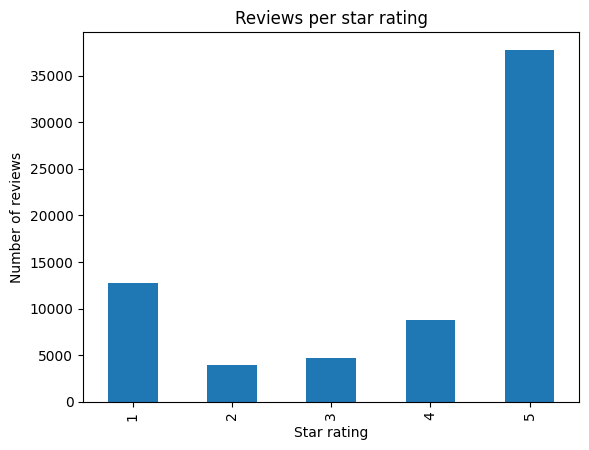

In [11]:
# Reviewing star-rating distribution
rating_counts = reviews["rating"].value_counts().sort_index()
print(rating_counts)

rating_counts.plot(kind="bar", title="Reviews per star rating")
plt.xlabel("Star rating")
plt.ylabel("Number of reviews")
plt.show()

In [12]:
# Review length in words
review_words = reviews["body"].fillna("").str.split().str.len()

print(review_words.describe())
print("Empty reviews:", (review_words == 0).sum())

count    67986.000000
mean        55.291795
std        119.500034
min          0.000000
25%          8.000000
50%         23.000000
75%         56.000000
max       5345.000000
Name: body, dtype: float64
Empty reviews: 26


In [13]:
# Checking reviews link to products by asin(product id)
is_linked = reviews["asin"].isin(items["asin"])

print("Reviews linked to a product:", is_linked.sum(), "of", len(reviews))
print("Products that have reviews:", reviews["asin"].nunique(), "of", len(items))

Reviews linked to a product: 67986 of 67986
Products that have reviews: 720 of 720


**Reviews dataset findings summary:**
- 720 phones from 10 brands (Samsung has 346). Only 4 missing brands.
- Total 67,986 reviews. All link to a product by `asin`. 26 empty reviews will be removed.
- Ratings are unbalanced: approx 68% positive (4–5 stars), approx 25% negative (1–2), approx 7% neutral (3).
- Most reviews are short (median 23 words). We will truncate the long reviews.